In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import camb
camb.__file__

'/Users/FeiGe/Research/cosmo_codes/CAMB_mnu_task_force/camb/__init__.py'

In [2]:
from scipy.interpolate import interp1d

## Fiducial cosmology

In [3]:
# set the fiducial cosmological parameters
# by default, WantSplitGeo = False, so it is just normal camb
pars = camb.set_params(H0=67.36, ombh2=0.02237, omch2=0.12, mnu=0.058, omk=0, tau=0.0544, As=2.1e-9, ns=0.9649, halofit_version='mead2020', nnu=3.044, num_massive_neutrinos=3)
pars.set_matter_power(kmax=10, k_per_logint=130)
pars.set_for_lmax(lmax=5000, lens_potential_accuracy=6, lens_margin=3000)
pars.set_accuracy(lAccuracyBoost=1.2, DoLateRadTruncation=False, min_l_logl_sampling=6000)

class: <CAMBparams>
 WantCls = True
 WantTransfer = True
 WantScalars = True
 WantTensors = False
 WantVectors = False
 WantDerivedParameters = True
 Want_cl_2D_array = True
 Want_CMB = True
 Want_CMB_lensing = True
 DoLensing = True
 NonLinear = NonLinear_lens
 Transfer: <TransferParams>
   high_precision = True
   accurate_massive_neutrinos = False
   kmax = 10.0
   k_per_logint = 130
   PK_num_redshifts = 1
   PK_redshifts = [0.0]
 want_zstar = False
 want_zdrag = False
 WantSplitGeo = False
 want_mono = True
 want_doppler = True
 want_isw = True
 want_quad = True
 min_l = 2
 max_l = 8000
 max_l_tensor = 600
 max_eta_k = 108000.0
 max_eta_k_tensor = 1200.0
 ombh2 = 0.02237
 omch2 = 0.12
 omk = 0.0
 omnuh2 = 0.0006233710182709436
 omnuh2_growth = 0.0
 nnu = 3.044
 H0 = 67.36
 TCMB = 2.7255
 YHe = 0.2458554819755239
 neutrino_hierarchy = 3
 num_massive_neutrinos = 3
 num_nu_massless = 0.0
 num_nu_massive = 3
 nu_mass_eigenstates = 1
 share_delta_neff = False
 nu_mass_degeneracies = [3

In [4]:
result0 = camb.get_transfer_functions(pars, only_time_sources=True)
result0.calc_power_spectra()
cl0_len = result0.get_total_cls(lmax=5000)
cl0_unl = result0.get_unlensed_total_cls(lmax=5000)
cl0_pp = result0.get_lens_potential_cls(lmax=5000)

In [5]:
# Compute the BAO observables at some redshifts from camb result

z_bao = np.array([0.295, 0.51, 0.706, 0.934, 1.321, 1.484, 2.33])

def calc_BAO(result):
    p_deriv = result.get_derived_params()
    baos = dict()
    for (i,z) in enumerate(z_bao):
        if i == 0:
            baos[z] = {"DV_over_rs": np.cbrt(
                ((1 + z) * result.angular_diameter_distance(z)) ** 2 *
                299792.458 * z / result.hubble_parameter(z)) / p_deriv['rdrag']}
        else:
            baos[z] = {
                "DM_over_rs": (1 + z) * result.angular_diameter_distance(z) / p_deriv['rdrag'],
                "DH_over_rs": 1 / result.h_of_z(z) / p_deriv['rdrag']
            }
    return baos

In [6]:
bao0 = calc_BAO(result0)
bao0

{np.float64(0.295): {'DV_over_rs': np.float64(8.056720229529176)},
 np.float64(0.51): {'DM_over_rs': np.float64(13.500085740900463),
  'DH_over_rs': 22.739814227070788},
 np.float64(0.706): {'DM_over_rs': np.float64(17.700327330532595),
  'DH_over_rs': 20.16943420332459},
 np.float64(0.934): {'DM_over_rs': np.float64(21.994478054801654),
  'DH_over_rs': 17.569288725744677},
 np.float64(1.321): {'DM_over_rs': np.float64(28.081581578312136),
  'DH_over_rs': 14.06527255847661},
 np.float64(1.484): {'DM_over_rs': np.float64(30.275594295782994),
  'DH_over_rs': 12.880445633847213},
 np.float64(2.33): {'DM_over_rs': np.float64(39.182909629706096),
  'DH_over_rs': 8.6164204089105}}

## Changing $\sum m_\nu^\mathrm{geo}$

In [7]:
pars = camb.set_params(H0=67.36, ombh2=0.02237, omch2=0.12, mnu=0.1, mnu_growth=0.058,omk=0, tau=0.0544, As=2.1e-9, ns=0.9649, halofit_version='mead2020', nnu=3.044, num_massive_neutrinos=3, WantSplitGeo = True)
pars.set_matter_power(kmax=10, k_per_logint=130)
pars.set_for_lmax(lmax=5000, lens_potential_accuracy=6, lens_margin=3000)
pars.set_accuracy(lAccuracyBoost=1.2, DoLateRadTruncation=False, min_l_logl_sampling=6000)

result2 = camb.get_transfer_functions(pars, only_time_sources=True)
result2.calc_power_spectra()
cl2_len = result2.get_total_cls(lmax=5000)
cl2_unl = result2.get_unlensed_total_cls(lmax=5000)
cl2_pp = result2.get_lens_potential_cls(lmax=5000)

In [8]:
bao2 = calc_BAO(result2)
bao2

{np.float64(0.295): {'DV_over_rs': np.float64(8.054685199595387)},
 np.float64(0.51): {'DM_over_rs': np.float64(13.495833693823794),
  'DH_over_rs': 22.72490647142571},
 np.float64(0.706): {'DM_over_rs': np.float64(17.692916122922874),
  'DH_over_rs': 20.15239087682981},
 np.float64(0.934): {'DM_over_rs': np.float64(21.983066983025363),
  'DH_over_rs': 17.5514855144822},
 np.float64(1.321): {'DM_over_rs': np.float64(28.06339586416215),
  'DH_over_rs': 14.048352763660311},
 np.float64(1.484): {'DM_over_rs': np.float64(30.254708275631742),
  'DH_over_rs': 12.864249917231552},
 np.float64(2.33): {'DM_over_rs': np.float64(39.150060834828544),
  'DH_over_rs': 8.60425145019806}}

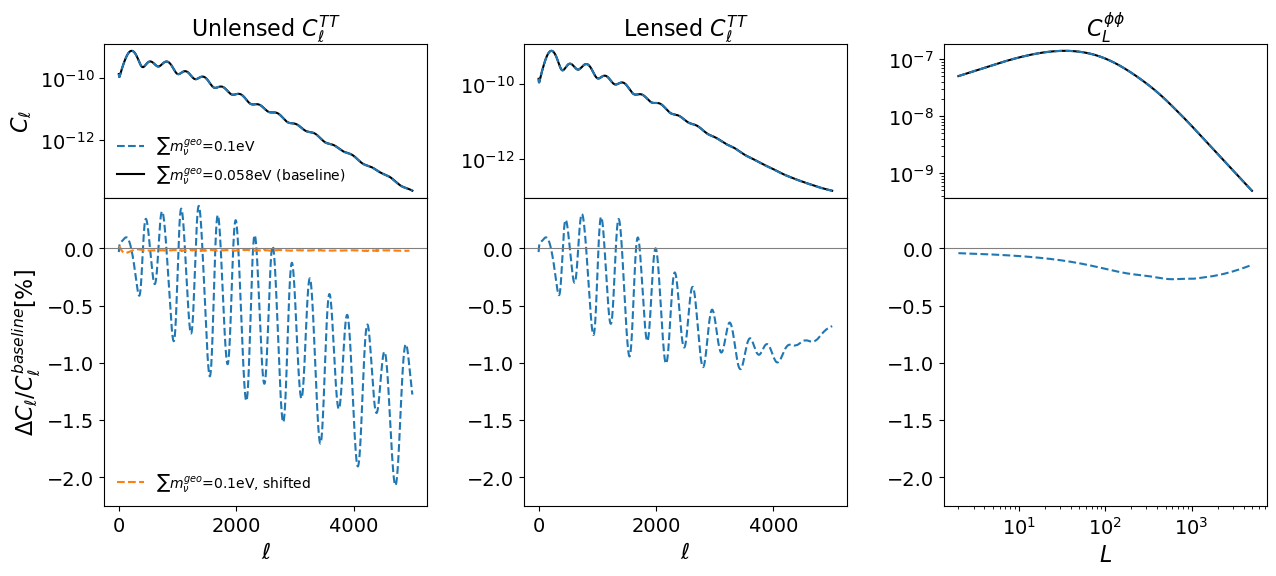

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6), sharex='col',height_ratios=[1, 2])

cl_plt = cl2_unl
fid_plt = cl0_unl

da0 = result0.get_derived_params()['DAstar']
da2 = result2.get_derived_params()['DAstar']

id = 0

ax[0, id].plot(np.arange(2,5001), fid_plt[2:, 0], c="k", label=r"$\sum m_\nu^{geo}$=0.058eV (baseline)")
ax[0, id].plot(np.arange(2,5001), cl_plt[2:, 0], ls="--", label=r"$\sum m_\nu^{geo}$=0.1eV")
ax[0, id].legend(reverse=True, frameon=False)
ax[0, id].set_yscale("log")
ax[0, id].set_title(r"Unlensed $C_\ell^{TT}$", fontsize=16)

ax[1, id].plot(np.arange(2,5001), (cl_plt[2:, 0]/fid_plt[2:, 0]-1)*100, ls="--")

tcl2 = interp1d(np.arange(2,5001)*da0/da2, cl_plt[2:, 0], bounds_error=False, fill_value="extrapolate")

ell = np.arange(10,4951)
ax[1, id].plot(ell, (tcl2(ell)/fid_plt[ell, 0]-1)*100, ls="--", label=r"$\sum m_\nu^{geo}$=0.1eV, shifted")
ax[1, id].legend(frameon=False)
ax[1, id].set_xlabel(r"$\ell$", fontsize=16)

ax[0, id].tick_params(axis='both', which='major', labelsize=14)
ax[1, id].tick_params(axis='both', which='major', labelsize=14)

cl_plt = cl2_len
fid_plt = cl0_len

id = 1

ax[0, id].plot(np.arange(2,5001), fid_plt[2:, 0], c="k", label="mnu=0.06eV")
ax[0, id].plot(np.arange(2,5001), cl_plt[2:, 0], ls="--", label="mnu=0.1eV")
ax[0, id].set_title(r"Lensed $C_\ell^{TT}$", fontsize=16)
ax[0, id].set_yscale("log")

ax[1, id].plot(np.arange(2,5001), (cl_plt[2:, 0]/fid_plt[2:, 0]-1)*100, ls="--")
ax[1, id].set_xlabel(r"$\ell$", fontsize=16)

ax[0, id].tick_params(axis='both', which='major', labelsize=14)
ax[1, id].tick_params(axis='both', which='major', labelsize=14)

cl_plt = cl2_pp
fid_plt = cl0_pp

id = 2

ax[0, id].plot(np.arange(2,5001), fid_plt[2:, 0], c="k", label="mnu=0.06eV")
ax[0, id].plot(np.arange(2,5001), cl_plt[2:, 0], ls="--", label="mnu=0.1eV")
ax[0, id].set_title(r"$C_L^{\phi\phi}$", fontsize=16)
ax[0, id].set_xscale("log")
ax[0, id].set_yscale("log")

ax[1, id].plot(np.arange(2,5001), (cl_plt[2:, 0]/fid_plt[2:, 0]-1)*100, ls="--")
ax[1, id].set_xlabel(r"$L$", fontsize=16)

tcl2 = interp1d(np.arange(2,5001)*da0/da2, cl_plt[2:, 0], bounds_error=False, fill_value="extrapolate")

ell = np.arange(10,4951)
plt.subplots_adjust(hspace=0, wspace=0.3)
ax[0,0].set_ylabel(r"$C_\ell$", fontsize=16)
ax[1,0].set_ylabel(r"$\Delta C_\ell / C_\ell^{baseline}[\%]$", fontsize=16)

ax[0, id].tick_params(axis='both', which='major', labelsize=14)
ax[1, id].tick_params(axis='both', which='major', labelsize=14)

ax[1,0].set_ylim(-2.25, 0.441)
ax[1,1].set_ylim(-2.25, 0.441)
ax[1,2].set_ylim(-2.25, 0.441)

ax[1,0].axhline(y=0, color='gray', ls="-", lw=0.8)
ax[1,1].axhline(y=0, color='gray', ls="-", lw=0.8)
ax[1,2].axhline(y=0, color='gray', ls="-", lw=0.8)

# plt.savefig("split_geo_effect.pdf", bbox_inches='tight')

In [10]:
def comp_back(
    H0: float | None = None,
    thetastar: float | None = None,
    mnu=0.058,
    mnu_growth=0.058
    ):
    if thetastar:
        if H0:
            raise ValueError("Cannot specify both H0 and thetastar")
        else:
            pars = camb.set_params(thetastar=thetastar, ombh2=0.02237, omch2=0.12, mnu=mnu, mnu_growth=mnu_growth, omk=0, tau=0.0544, As=2.1e-9, ns=0.9649, halofit_version='mead2020', nnu=3.044, num_massive_neutrinos=3, WantSplitGeo = True)
    else:
        if H0:
            pars = camb.set_params(H0=67.36, ombh2=0.02237, omch2=0.12, mnu=mnu, mnu_growth=mnu_growth, omk=0, tau=0.0544, As=2.1e-9, ns=0.9649, halofit_version='mead2020', nnu=3.044, num_massive_neutrinos=3, WantSplitGeo = True)
        else:
            raise ValueError("Must specify either H0 or thetastar")

    return camb.get_background(pars)


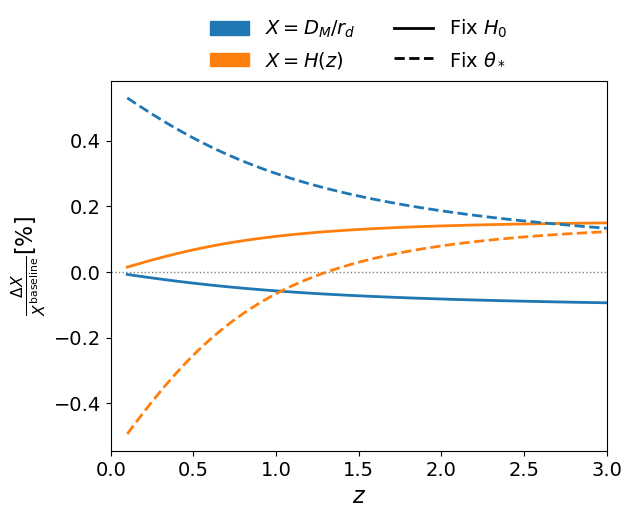

In [11]:
z = np.linspace(0.1, 3, 101)

b1 = comp_back(H0=67.36)
b2 = comp_back(H0=67.36, mnu=0.1)

bt1 = comp_back(thetastar=1.0411e-2)
bt2 = comp_back(thetastar=1.0411e-2, mnu=0.1)

plt.ylabel(r"$\frac{\Delta X}{X^\mathrm{baseline}}\mathrm{[\%]}$", fontsize=16)
plt.xlabel(r"$z$", fontsize=16)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.xlim(0, 3)
plt.axhline(0, ls=":", c="gray", lw=1)

plt.plot(z, (b2.angular_diameter_distance(z)/b1.angular_diameter_distance(z)-1)*100, label=r"$X=D_M/r_d$", lw=2)
plt.plot(z, (b2.h_of_z(z)/b1.h_of_z(z)-1)*100, label=r"$X=H(z)$", lw=2)

plt.plot(z, (bt2.angular_diameter_distance(z)/bt1.angular_diameter_distance(z)-1)*100, label=r"$X=D_M/r_d$", lw=2, ls="--", c="C0")
plt.plot(z, (bt2.h_of_z(z)/bt1.h_of_z(z)-1)*100, label=r"$X=H(z)$", lw=2, ls="--", c="C1")

l1 = mlines.Line2D([], [], color='k', ls="-", lw=2,label="fix H0")
l2 = mlines.Line2D([], [], color='k', ls="--", lw=2,label="fix θ*")
p1 = mpatches.Patch(color="C0", label=r"$X=D_M/r_d$")
p2 = mpatches.Patch(color="C1", label=r"$X=H(z)$")

plt.legend([p1, p2, l1, l2], [
    r"$X=D_M/r_d$",
    r"$X=H(z)$",
    r"Fix $H_0$",
    r"Fix $\theta_*$",
    ],
    ncol=2, fontsize=14, bbox_to_anchor=[0.5, 1.1], loc="center", frameon=False)

# plt.savefig("bao_mnu.pdf", dpi="figure", bbox_inches="tight")

## Changing $\sum m_\nu^\mathrm{growth}$

In [12]:
pars = camb.set_params(H0=67.36, ombh2=0.02237, omch2=0.12, mnu=0.058, mnu_growth=0.1,omk=0, tau=0.0544, As=2.1e-9, ns=0.9649, halofit_version='mead2020', nnu=3.044, num_massive_neutrinos=3, WantSplitGeo = True)
pars.set_matter_power(kmax=10, k_per_logint=130)
pars.set_for_lmax(lmax=5000, lens_potential_accuracy=6, lens_margin=3000)
pars.set_accuracy(lAccuracyBoost=1.2, DoLateRadTruncation=False, min_l_logl_sampling=6000)

result1 = camb.get_transfer_functions(pars, only_time_sources=True)
result1.calc_power_spectra()
cl1_len = result1.get_total_cls(lmax=5000)
cl1_unl = result1.get_unlensed_total_cls(lmax=5000)
cl1_pp = result1.get_lens_potential_cls(lmax=5000)

In [13]:
bao1 = calc_BAO(result1)
bao1

{np.float64(0.295): {'DV_over_rs': np.float64(8.056720229529176)},
 np.float64(0.51): {'DM_over_rs': np.float64(13.500085740900463),
  'DH_over_rs': 22.739814227070788},
 np.float64(0.706): {'DM_over_rs': np.float64(17.700327330532595),
  'DH_over_rs': 20.16943420332459},
 np.float64(0.934): {'DM_over_rs': np.float64(21.994478054801654),
  'DH_over_rs': 17.569288725744677},
 np.float64(1.321): {'DM_over_rs': np.float64(28.081581578312136),
  'DH_over_rs': 14.06527255847661},
 np.float64(1.484): {'DM_over_rs': np.float64(30.275594295782994),
  'DH_over_rs': 12.880445633847213},
 np.float64(2.33): {'DM_over_rs': np.float64(39.182909629706096),
  'DH_over_rs': 8.6164204089105}}

In [14]:
# Check if the bao from result1 is the same as the fiducial result
# They should be the same, because the mnu_geo and other cosmological parameters are the same
# Only mnu_growth is changed in this result compared to fiducial result
bao1 == bao0

True

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


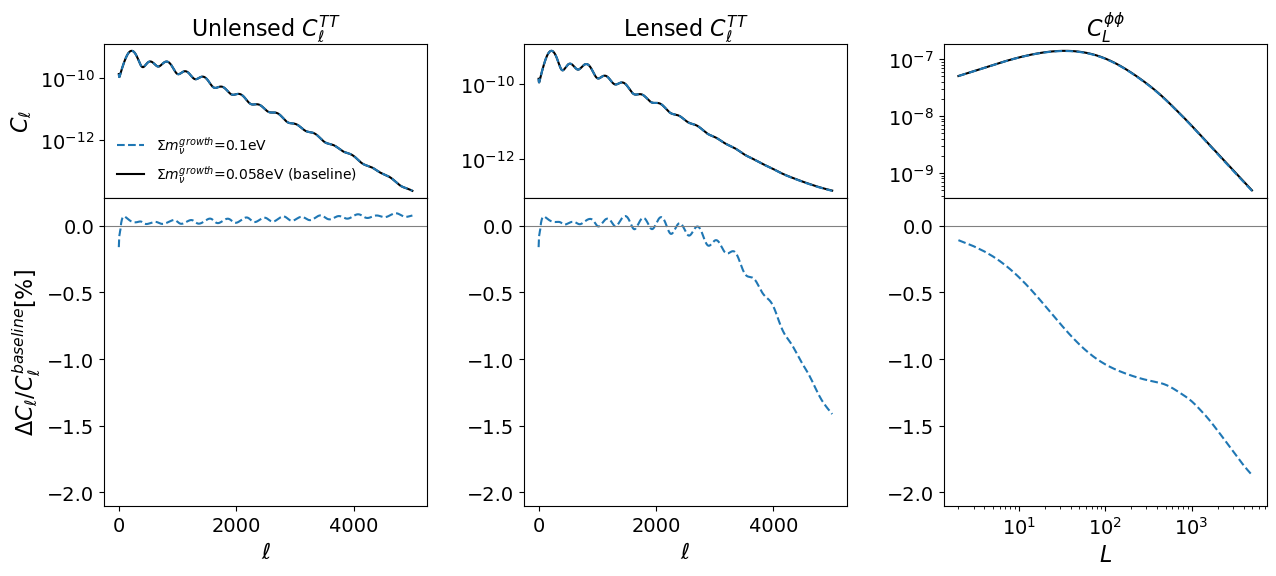

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6), sharex='col',height_ratios=[1, 2])

cl_alt = cl1_unl
fid_plt = cl0_unl

id = 0

ax[0, id].plot(np.arange(2,5001), fid_plt[2:, 0], c="k", label=r"$\Sigma m_\nu^{growth}$=0.058eV (baseline)")
ax[0, id].plot(np.arange(2,5001), cl_alt[2:, 0], ls="--", label=r"$\Sigma m_\nu^{growth}$=0.1eV")

ax[0, id].legend(reverse=True, frameon=False)
ax[0, id].set_yscale("log")
ax[0, id].set_title(r"Unlensed $C_\ell^{TT}$", fontsize=16)

ax[1, id].plot(np.arange(2,5001), (cl_alt[2:, 0]/fid_plt[2:, 0]-1)*100, ls="--")
ax[1, id].legend(frameon=False)
ax[1, id].set_xlabel(r"$\ell$", fontsize=16)

ax[0, id].tick_params(axis='both', which='major', labelsize=14)
ax[1, id].tick_params(axis='both', which='major', labelsize=14)

cl_alt = cl1_len
fid_plt = cl0_len

id = 1

ax[0, id].plot(np.arange(2,5001), fid_plt[2:, 0], c="k")
ax[0, id].plot(np.arange(2,5001), cl_alt[2:, 0], ls="--")
ax[0, id].set_title(r"Lensed $C_\ell^{TT}$", fontsize=16)
ax[0, id].set_yscale("log")

ax[1, id].plot(np.arange(2,5001), (cl_alt[2:, 0]/fid_plt[2:, 0]-1)*100, ls="--")
ax[1, id].set_xlabel(r"$\ell$", fontsize=16)

ax[0, id].tick_params(axis='both', which='major', labelsize=14)
ax[1, id].tick_params(axis='both', which='major', labelsize=14)

cl_alt = cl1_pp
fid_plt = cl0_pp

id = 2

ax[0, id].plot(np.arange(2,5001), fid_plt[2:, 0], c="k")
ax[0, id].plot(np.arange(2,5001), cl_alt[2:, 0], ls="--")
ax[0, id].set_title(r"$C_L^{\phi\phi}$", fontsize=16)
ax[0, id].set_xscale("log")
ax[0, id].set_yscale("log")

ax[1, id].plot(np.arange(2,5001), (cl_alt[2:, 0]/fid_plt[2:, 0]-1)*100, ls="--")
ax[1, id].set_xlabel(r"$L$", fontsize=16)

plt.subplots_adjust(hspace=0, wspace=0.3)
ax[0,0].set_ylabel(r"$C_\ell$", fontsize=16)
ax[1,0].set_ylabel(r"$\Delta C_\ell / C_\ell^{baseline}[\%]$", fontsize=16)

ax[0, id].tick_params(axis='both', which='major', labelsize=14)
ax[1, id].tick_params(axis='both', which='major', labelsize=14)

ax[1,0].set_ylim(-2.1, 0.21)
ax[1,1].set_ylim(-2.1, 0.21)
ax[1,2].set_ylim(-2.1, 0.21)

ax[1,0].axhline(y=0, color='gray', ls="-", lw=0.8)
ax[1,1].axhline(y=0, color='gray', ls="-", lw=0.8)
ax[1,2].axhline(y=0, color='gray', ls="-", lw=0.8)

# plt.savefig("split_growth_effect.pdf", bbox_inches='tight')